In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from analysis_tools.analysis import analyze_vertex_regression
from analysis_tools.plotting import (
    add_cylindrical_detector_3d,
    plot_event_3d,
    plot_unrolled_cylindrical_event,
    plot_vertex_errors,
    save_figure,
)

OUTPUT_DIRECTORY = Path("outputs/notebook")
RANDOM_SEED = 4242
rng = np.random.default_rng(RANDOM_SEED)

In [2]:
event_count = 5_000

true_radius = 1_400.0 * np.sqrt(rng.uniform(0.0, 1.0, event_count))
true_phi = rng.uniform(-np.pi, np.pi, event_count)
true_z = rng.uniform(-1_500.0, 1_500.0, event_count)

targets_cm = np.column_stack(
    (
        true_radius * np.cos(true_phi),
        true_radius * np.sin(true_phi),
        true_z,
    )
)

predictions_cm = targets_cm + rng.normal(
    loc=[3.0, -2.0, 5.0],
    scale=[35.0, 35.0, 45.0],
    size=(event_count, 3),
)

result = analyze_vertex_regression(
    predictions_cm,
    targets_cm,
    detector_radius=1_690.0,
    detector_half_height=1_810.0,
)

print(f"Events: {result.event_count:,}")
print(f"Median 3D error: {np.median(result.errors):.2f} cm")
print(f"68% quantile: {np.quantile(result.errors, 0.68):.2f} cm")

Events: 5,000
Median 3D error: 58.18 cm
68% quantile: 71.40 cm


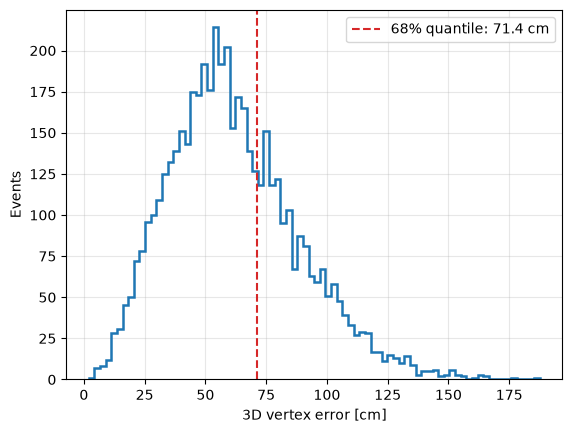

In [3]:
figure, axis = plot_vertex_errors(
    result.errors,
    bins=80,
    xlabel="3D vertex error [cm]",
    color="tab:blue",
    linewidth=1.8,
)

quantile_68 = np.quantile(result.errors, 0.68)
axis.axvline(
    quantile_68,
    color="tab:red",
    linestyle="--",
    label=f"68% quantile: {quantile_68:.1f} cm",
)
axis.grid(alpha=0.3)
axis.legend()
plt.show()

In [4]:
detector_radius = 10.0
detector_half_height = 12.0
number_of_barrel_pmts = 800
number_of_endcap_pmts = 200
number_of_hits = 80

barrel_phi = rng.uniform(-np.pi, np.pi, number_of_barrel_pmts)
barrel_z = rng.uniform(
    -detector_half_height, detector_half_height, number_of_barrel_pmts
)
barrel_positions = np.column_stack(
    (
        detector_radius * np.cos(barrel_phi),
        detector_radius * np.sin(barrel_phi),
        barrel_z,
    )
)

endcap_phi = rng.uniform(-np.pi, np.pi, number_of_endcap_pmts)
endcap_radius = detector_radius * np.sqrt(rng.uniform(0.0, 1.0, number_of_endcap_pmts))
endcap_z = np.where(
    np.arange(number_of_endcap_pmts) % 2 == 0,
    detector_half_height,
    -detector_half_height,
)
endcap_positions = np.column_stack(
    (
        endcap_radius * np.cos(endcap_phi),
        endcap_radius * np.sin(endcap_phi),
        endcap_z,
    )
)

pmt_positions = np.concatenate((barrel_positions, endcap_positions), axis=0)
hit_indices = rng.choice(len(pmt_positions), size=number_of_hits, replace=False)
hit_positions = pmt_positions[hit_indices]
charges = rng.gamma(shape=2.0, scale=4.0, size=number_of_hits)

print(f"PMTs: {len(pmt_positions):,}")
print(f"Hits: {len(hit_positions):,}")

PMTs: 1,000
Hits: 80


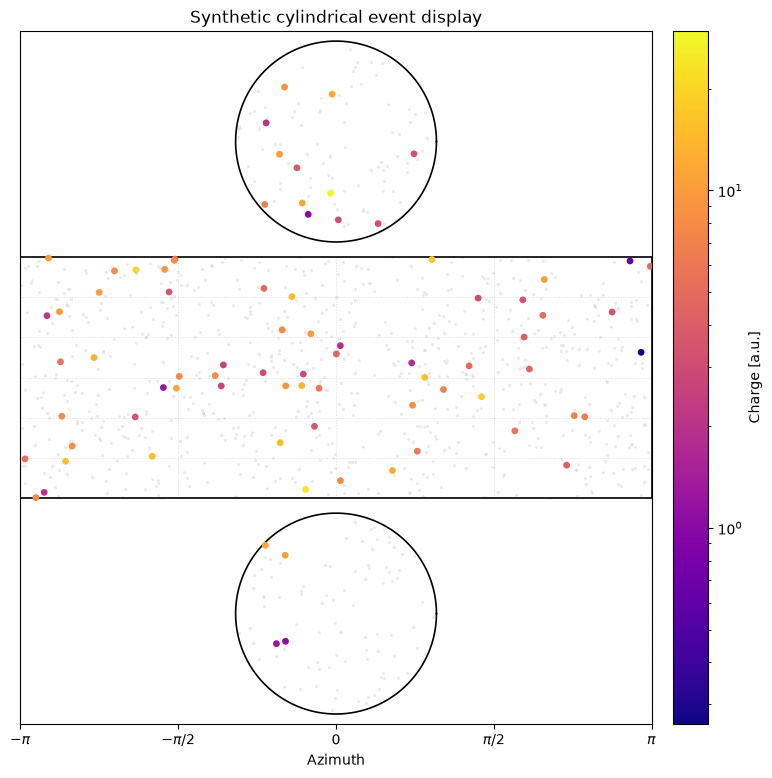

In [5]:
figure_2d, axis_2d = plot_unrolled_cylindrical_event(
    charges,
    hit_positions,
    all_pmt_coordinates=pmt_positions,
    radius=detector_radius,
    half_height=detector_half_height,
    axis=2,
    title="Synthetic cylindrical event display",
    color_label="Charge [a.u.]",
    cmap="plasma",
    marker_size=24.0,
    show_grid=True,
)
plt.show()

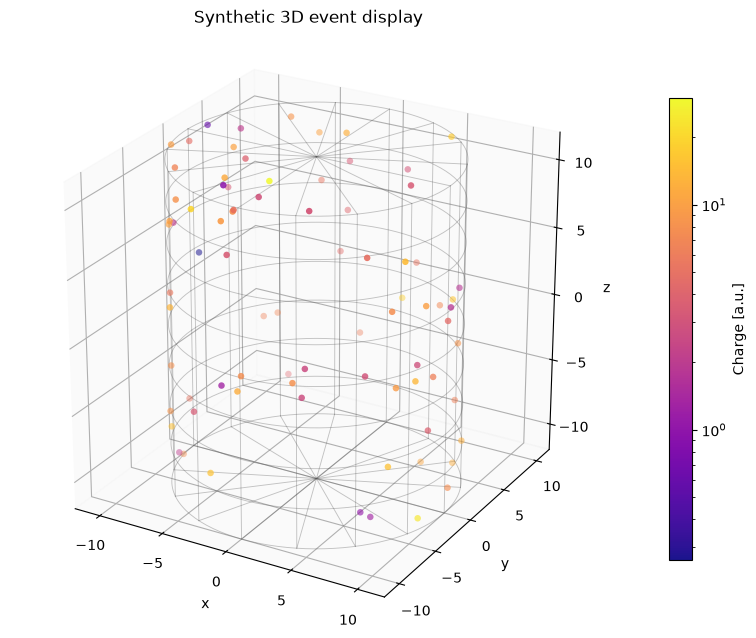

In [6]:
figure_3d, axis_3d = plot_event_3d(
    charges,
    hit_positions,
    all_pmt_coordinates=pmt_positions,
    title="Synthetic 3D event display",
    color_label="Charge [a.u.]",
    cmap="plasma",
    marker_size=22.0,
    background_size=2.0,
    background_alpha=0.035,
    show_axes=True,
    show_grid=True,
    show_background_panes=True,
    equal_aspect=True,
    view_elevation=25.0,
    view_azimuth=-60.0,
    axis_labels=("x", "y", "z"),
)

add_cylindrical_detector_3d(
    axis_3d,
    radius=detector_radius,
    half_height=detector_half_height,
    axis=2,
    color="0.35",
    linewidth=0.65,
    alpha=0.35,
)
plt.show()

In [7]:
save_figure(
    figure_2d,
    OUTPUT_DIRECTORY / "event_display_2d.png",
    dpi=200,
)
save_figure(
    figure_3d,
    OUTPUT_DIRECTORY / "event_display_3d.png",
    dpi=200,
)
print(f"Saved figures to: {OUTPUT_DIRECTORY}")

Saved figures to: outputs/notebook
